### Problem 1.1- Plot Optical Sensor Signal
This section loads the fingertip sensor data and plots reflected-light intensity against time in seconds.

In [1]:
import pandas as pd

signal = pd.read_csv(
    "data/heart_beat_signal.csv",
    header=None,
    names=["time_s","amplitude"]
)

signal.head()

,time_s,amplitude
0,0.033367,32.808
1,0.066733,32.793
2,0.100100,33.042
3,0.133470,32.232
4,0.166830,29.150


In [9]:
sample_count = len(signal)
duration_s = signal["time_s"].iloc[-1] - signal["time_s"].iloc[0]

print(f"Number of samples: {sample_count}")
print(f"Time between first and last sample: {duration_s:.2f} s")

Number of samples: 913
Time between first and last sample: 30.43 s


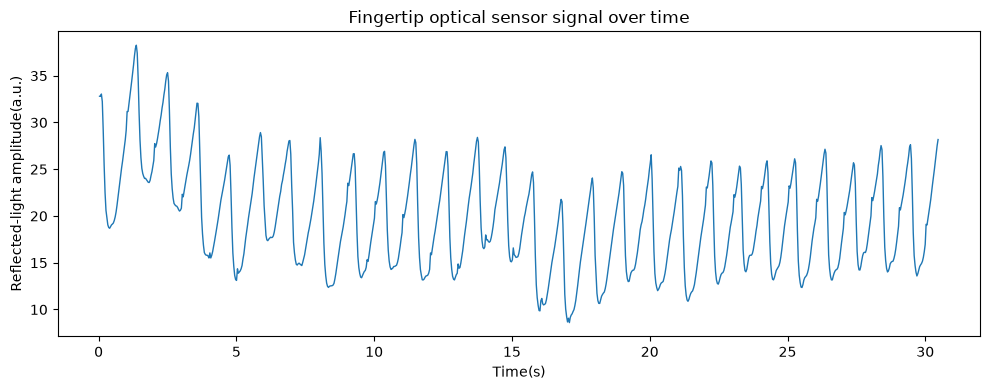

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(signal["time_s"], signal["amplitude"], linewidth=1)

plt.xlabel("Time(s)")
plt.ylabel("Reflected-light amplitude(a.u.)")
plt.title("Fingertip optical sensor signal over time")

plt.tight_layout()
plt.savefig("problem1_1_optical_signal.png", dpi=300)
plt.show()



### Problem 1.2 - Estimate Heart Rate Using FFT
This section uses a fast Fourier transform (FFT) to find the dominant pulse frequency optical signal and convert it ro beats per minute.

In [3]:
import numpy as np

time_s = signal["time_s"].to_numpy()
amplitude = signal["amplitude"].to_numpy()

dt = np.mean(np.diff(time_s))

centred_signal = amplitude - amplitude.mean()
windowed_signal = centred_signal * np.hanning(len(amplitude))

frequencies = np.fft.rfftfreq(len(amplitude), d=dt)
magnitude = np.abs(np.fft.rfft(windowed_signal))

search_band = (frequencies >= 0.5) & (frequencies <= 4.0)
band_frequencies = frequencies[search_band]
band_magnitudes = magnitude[search_band]

peak_index = np.argmax(band_magnitudes)
peak_frequency = band_frequencies[peak_index]
heart_rate_bpm = peak_frequency * 60

print(f"Sampling rate:{1 / dt:.2f} Hz")
print(f"Dominant frequency: {peak_frequency:.3f} Hz")
print(f"Estimated heart rate: {heart_rate_bpm:.1f} bpm")


Sampling rate:29.97 Hz
Dominant frequency: 0.919 Hz
Estimated heart rate: 55.1 bpm


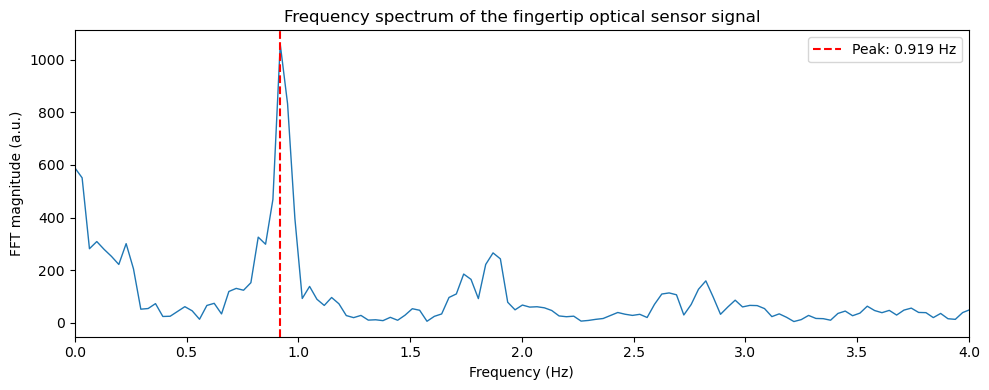

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(frequencies, magnitude, linewidth=1)
plt.axvline(peak_frequency, color="red", linestyle="--", label=f"Peak: {peak_frequency:.3f} Hz")

plt.xlim(0, 4)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT magnitude (a.u.)")
plt.title("Frequency spectrum of the fingertip optical sensor signal")
plt.legend()

plt.tight_layout()
plt.savefig("problem1_2_optical_fft.png", dpi=300)
plt.show()


### Problem 2.1 — Mean grayscale over time

In [5]:
import cv2
video = cv2.VideoCapture("data/video_of_finger.MOV")
fps = video.get(cv2.CAP_PROP_FPS)
ok, frame = video.read()
video.release()
print(f"Video frame rate: {fps:.2f} fps")

Video frame rate: 29.98 fps


In [6]:
if not ok:
    raise RuntimeError("Could not read the first video frame.")

gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
first_mean = gray_frame.mean()
print(f"First-frame mean grayscale: {first_mean:.2f}")

First-frame mean grayscale: 69.50


In [7]:
video = cv2.VideoCapture("data/video_of_finger.MOV")
video_time_s = []
video_mean_gray = []

while True:
    ok, frame = video.read()
    if not ok:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    video_mean_gray.append(gray.mean())
    video_time_s.append(video.get(cv2.CAP_PROP_POS_MSEC) / 1000)

video.release()

video_time_s = np.array(video_time_s)
video_mean_gray = np.array(video_mean_gray)

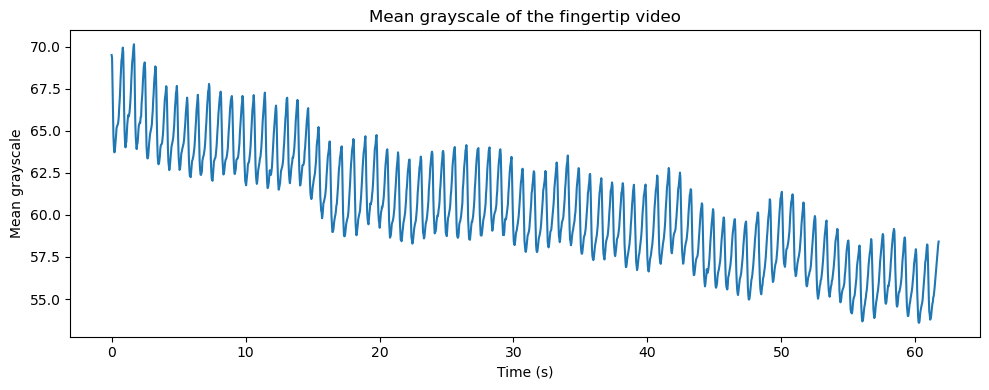

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(video_time_s, video_mean_gray)
plt.xlabel("Time (s)")
plt.ylabel("Mean grayscale")
plt.title("Mean grayscale of the fingertip video")
plt.tight_layout()
plt.savefig("problem2_1_video_grayscale.png", dpi=300)
plt.show()

### Problem 2.2a - Check and Pre-process the Grayscale Signal

In [9]:
def check_signal(time_s, values, name):
    t = np.asarray(time_s, dtype=float)
    y = np.asarray(values, dtype=float)

    if len(t) < 2 or len(t) != len(y):
         raise ValueError("Invalid signal length")
    if not np.isfinite(t).all() or not np.isfinite(y).all():
        raise ValueError("Invalid or missing data")

    dt = np.diff(t)
    if np.any(dt <= 0):
        raise ValueError("Time must be increasing")

    fs = 1/ np.mean(dt)

    print(f"{name}: {len(y)} samples, {fs:.2f} Hz")
    print(f"Sampling interval: {dt.min():.4f} to {dt.max():.4f} s")

    if fs <= 8:
        raise ValueError("Sampling rate too low for 240 bpm")

    return fs

fs_video=check_signal(video_time_s, video_mean_gray,"Video")

Video: 1852 samples, 29.98 Hz
Sampling interval: 0.0333 to 0.0350 s


In [10]:
from types import SimpleNamespace
from scipy.signal import butter, sosfiltfilt

HR_BAND_HZ = (0.5, 4.0)

def preprocess(time_s, values, fs):
    t = np.asarray(time_s, dtype=float)
    y = np.asarray(values, dtype=float)

    t = t - t[0]
    t_uniform = np.arange(len(t)) / fs
    y_uniform = np.interp(t_uniform, t, y)

    sos = butter(3, HR_BAND_HZ, btype="bandpass", fs=fs, output="sos")
    y_filtered = sosfiltfilt(sos, y_uniform)

    std = y_filtered.std()
    if std == 0:
        raise ValueError("Filtered signal has zero variation")

    x = (y_filtered - y_filtered.mean())/ std

    return SimpleNamespace(t=t_uniform, raw=y_uniform,
                           x=x, fs=fs, band=HR_BAND_HZ)

sig_video = preprocess(video_time_s,video_mean_gray,fs_video)

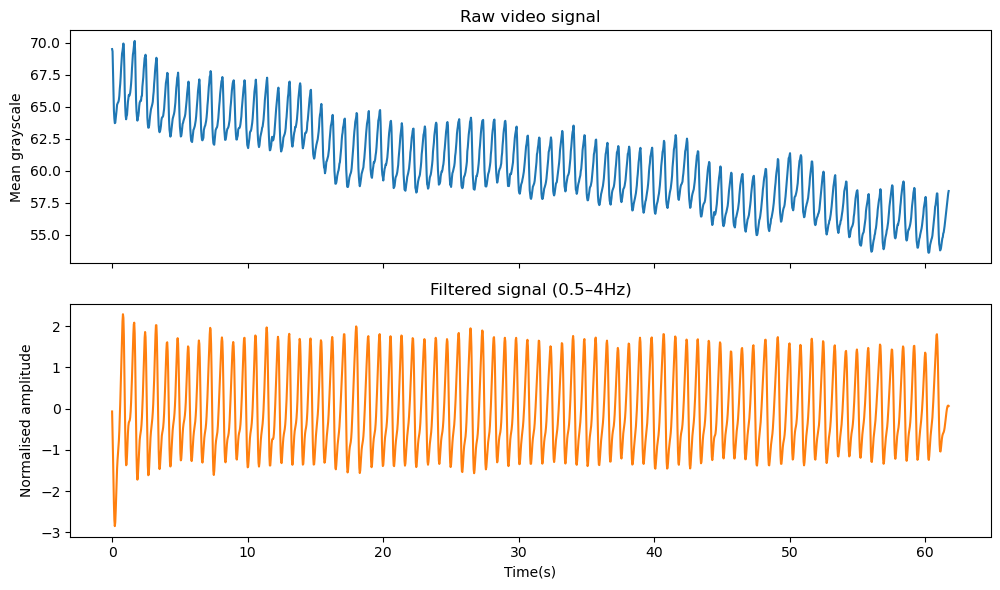

Sampling rate: 29.98 Hz
Samples: 1852
Mean: 0.00, SD: 1.00


In [11]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].plot(sig_video.t, sig_video.raw)
ax[0].set_title("Raw video signal")
ax[0].set_ylabel("Mean grayscale")

ax[1].plot(sig_video.t, sig_video.x, color="tab:orange")
ax[1].set_title("Filtered signal (0.5–4Hz)")
ax[1].set_xlabel("Time(s)")
ax[1].set_ylabel("Normalised amplitude")

plt.tight_layout()
plt.savefig("problem2_2a_preprocessed_signal.png",dpi=300)
plt.show()

print(f"Sampling rate: {sig_video.fs:.2f} Hz")
print(f"Samples: {len(sig_video.x)}")
print(f"Mean: {sig_video.x.mean():.2f}, SD: {sig_video.x.std():.2f}")

### Problem 2.2b - Frequency analysis and heart-rate estimation

This section estimates heart rate from the preprocessed mean greyscale signal. The FFT shows which frequencies contribute most strongly to the brightness fluctuatuons. We identify the frequency with the largest FFT magnitude within 0.5-4 Hz and multiply it by 60 to estimate heart rate in beats per minute (bpm).

In [16]:
video_signal = sig_video.x
video_dt = 1 / sig_video.fs
band_low, band_high = sig_video.band

video_fft = np.fft.fft(video_signal)
video_frequencies = np.fft.fftfreq(len(video_signal), d=video_dt)
video_magnitudes = np.abs(video_fft)

in_heart_rate_band = (video_frequencies >= band_low) & (
    video_frequencies <= band_high
)
band_frequencies = video_frequencies[in_heart_rate_band]
band_magnitudes = video_magnitudes[in_heart_rate_band]

video_peak_index = np.argmax(band_magnitudes)
video_peak_hz = band_frequencies[video_peak_index]
video_heart_rate_bpm = 60 * video_peak_hz

print(f"Dominant video frequency: {video_peak_hz: .3f} Hz")
print(f"Estimated video heart rate: {video_heart_rate_bpm: .1f} bpm")

Dominant video frequency:  1.198 Hz
Estimated video heart rate:  71.9 bpm


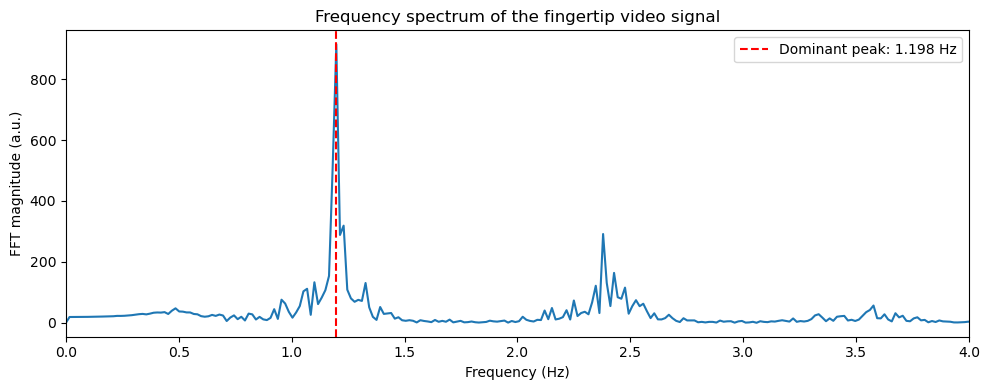

In [17]:
nonnegative_frequencies = video_frequencies >= 0

plt.figure(figsize=(10, 4))
plt.plot(
    video_frequencies[nonnegative_frequencies],
    video_magnitudes[nonnegative_frequencies],
)
plt.axvline(
    video_peak_hz,
    color="red",
    linestyle="--",
    label=f"Dominant peak: {video_peak_hz:.3f} Hz",
)
plt.xlim(0, band_high)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT magnitude (a.u.)")
plt.title("Frequency spectrum of the fingertip video signal")
plt.legend()
plt.tight_layout()
plt.savefig("problem2_2b_video_fft.png", dpi=300)
plt.show()